## Simulate Cell Lineage Tree

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
import string

diff_map_edges = [
    ("A", "B"),
    ("A", "C"),
    ("C", "D"),
    ("C", "E"),
]

diff_times = [0.25, None, 0.60, None, None]

diff_T = nx.DiGraph()

for i, t in enumerate(diff_times):
    diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

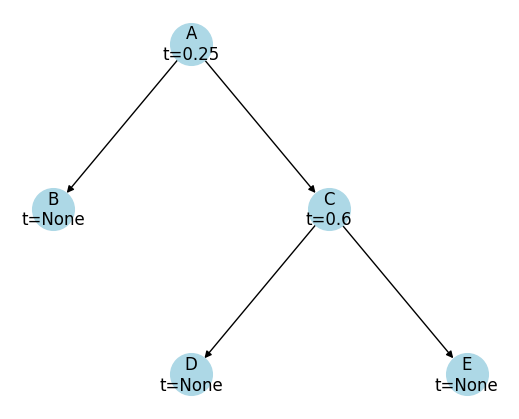

In [3]:
pos = nx.nx_agraph.graphviz_layout(diff_T, prog="dot")

node_labels = {
    n: f"{n}\nt={diff_T.nodes[n]['diff_time']}"
    for n in diff_T.nodes
}

plt.figure(figsize=(5, 4))

nx.draw(
    diff_T,
    pos,
    with_labels=False,
    node_size=900,
    node_color="lightblue",
    arrows=True
)

# Node labels (ID + time)
nx.draw_networkx_labels(
    diff_T,
    pos,
    labels=node_labels
)

plt.show()


In [4]:
edges = [
    (0, 1, 0.2),
    (1, 2, 0.1),
    (1, 3, 0.3),
    (2, 4, 0.7),
    (2, 5, 0.4),
    (3, 8, 0.5),
    (3, 9, 0.5),
    (5, 6, 0.3),
    (5, 7, 0.3),
]

In [5]:
lineage_tip_types = {
    4: 'D',
    6: 'E',
    7: 'E',
    8: 'B',
    9: 'B',
}

In [6]:
cell_lineage_T = nx.DiGraph()

for s, e, w in edges:
    cell_lineage_T.add_edge(s, e, weight=w)

for tip, type in lineage_tip_types.items():
    cell_lineage_T.nodes[tip]["type"] = type

cell_lineage_T

In [7]:
import networkx as nx
import matplotlib.pyplot as plt

def draw_ultrametric_tree(T, root, diff_T=None):
    
    # Heights from root
    height = {}

    def dfs(n, h):
        height[n] = h
        for c in T.successors(n):
            dfs(c, h + T[n][c]["weight"])

    dfs(root, 0.0)

    # X positions: leaves first
    leaves = [n for n in T.nodes if T.out_degree(n) == 0]
    x = {leaf: i for i, leaf in enumerate(sorted(leaves))}

    def assign_x(n):
        if n in x:
            return x[n]
        children = list(T.successors(n))
        x[n] = sum(assign_x(c) for c in children) / len(children)
        return x[n]

    assign_x(root)

    y = {n: -height[n] for n in T.nodes}

    fig, ax = plt.subplots(figsize=(8, 5))

    # Draw rectangular structure
    for u in T.nodes:
        children = list(T.successors(u))
        if not children:
            continue

        xs = [x[c] for c in children]

        # horizontal bar at parent height
        ax.plot([min(xs), max(xs)], [y[u], y[u]], color="black")

        # vertical branches + weights
        for c in children:
            ax.plot([x[c], x[c]], [y[u], y[c]], color="black")

            # edge weight label (midpoint of vertical segment)
            w = T[u][c]["weight"]
            y_mid = (y[u] + y[c]) / 2
            ax.text(
                x[c] + 0.05,
                y_mid,
                f"{w}",
                va="center",
                fontsize=8,
            )

    # Draw nodes
    for n in T.nodes:
        ax.scatter(x[n], y[n], color="black", zorder=3)
        node_str = str(n)
        if "type" in T.nodes[n]:
            node_str += "\n(" + (T.nodes[n]["type"]) + ")"
        ax.text(x[n] - 0.07, y[n] + 0.02, node_str, ha="center", fontsize=9)

    if diff_T is not None:
        for n in diff_T.nodes:
            dt = diff_T.nodes[n].get("diff_time")
            if dt is not None:
                ax.axhline(-dt)

                children = list(diff_T.successors(n))
                if not children: continue
                label = str(n) + "→ {" +  ', '.join(map(str, children)) + "}"
                ax.text(
                    -0.15,
                    -dt + 0.01,
                    label,
                    fontsize=9
                )

    # ax.set_ylim(-1.0, 0.0)

    major_ticks = np.linspace(0, 1, 21)
    ax.set_yticks(major_ticks - 1)
    ax.set_yticklabels([f"{t:.2f}" for t in major_ticks], fontsize=8)

    # ax.set_ylabel("Time")

    ax.set_xticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    
    plt.show()


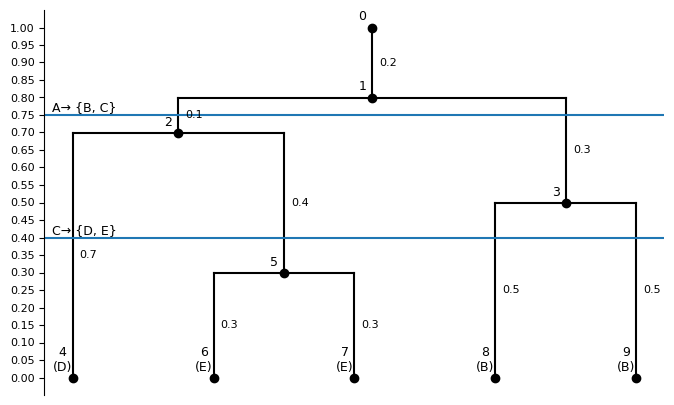

In [8]:
draw_ultrametric_tree(cell_lineage_T, root=0, diff_T=diff_T)

In [9]:
def add_node_times(cell_lineage_T, root=0):
    distances = nx.single_source_dijkstra_path_length(cell_lineage_T, root, weight='weight')
    for node, dist in distances.items():
        cell_lineage_T.nodes[node]['T'] = 1 - dist
    
    return cell_lineage_T

cell_lineage_T = add_node_times(cell_lineage_T)

In [10]:
def type_internal_nodes(cell_lineage_T, diff_T):

    lineage_nodes = list(cell_lineage_T.nodes(data=True))
    diff_nodes = list(diff_T.nodes(data=True))
    for d in diff_nodes:
        if d[1]['diff_time'] is not None:
            d[1]['diff_time_rev'] = 1 - d[1]['diff_time']
        else:
            d[1]['diff_time_rev'] = None

    combined_list = lineage_nodes + diff_nodes

    combined_list = [
        (n, d) for n, d in combined_list 
        if d.get('T') is not None or d.get('diff_time_rev') is not None
    ]
    combined_sorted = sorted(
        combined_list,
        key=lambda x: x[1].get('T', x[1].get('diff_time_rev'))
    )


    transform_map = {}

    for node in combined_sorted:
        node_id, node_data = node

        if 'T' in node_data:

            if 'type' in node_data:
                continue

            children = list(cell_lineage_T.successors(node_id))

            children_types = [cell_lineage_T.nodes[ch]['type'] 
                            for ch in children 
                            if 'type' in cell_lineage_T.nodes[ch]]
            
            children_types = [transform_map.get(t, t) for t in children_types]

            unique_types = list(set(children_types))

            if len(unique_types) > 1:
                raise ValueError(f"Children have > 1 types {unique_types}")
            
            cell_lineage_T.nodes[node_id]["type"] = unique_types[0]


        elif 'diff_time_rev' in node_data:

            children = list(diff_T.successors(node_id))
            for child in children:
                transform_map[child] = node_id
            
            for key, value in list(transform_map.items()):
                for child in children:
                    if child == value:
                        transform_map[key] = node_id
    
    return cell_lineage_T


cell_lineage_T = type_internal_nodes(cell_lineage_T, diff_T)

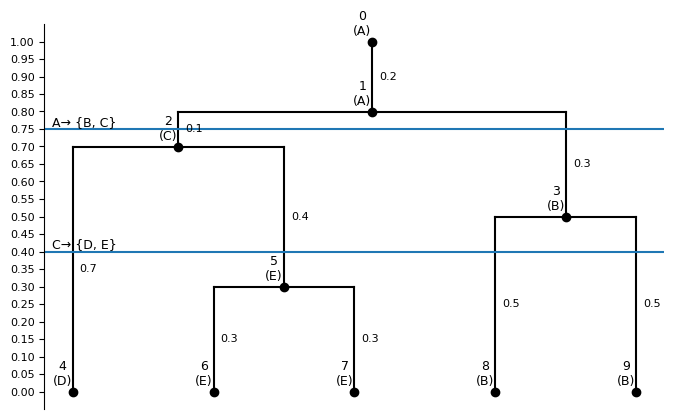

In [11]:
draw_ultrametric_tree(cell_lineage_T, root=0, diff_T=diff_T)

## Calculate Likelihood

In [41]:
from math import exp

def calculate_likelihood(
    birth_rates: dict,
    death_rates: dict,
    transition_probabilities: pd.DataFrame,
    cell_lineage_T,
    diff_T,
    diff_T_root='A',
):
    prob = 1
    # lambdas
    internal_nodes = [n for n in cell_lineage_T.nodes 
                      if list(cell_lineage_T.successors(n)) and list(cell_lineage_T.predecessors(n))
                      ]

    for node in internal_nodes:
        prob *= birth_rates[cell_lineage_T.nodes[node]['type']]
    
    # edges
    # calculate end Es:
    end_Es = {}
    Cks = {}
    dfs_nodes = list(nx.dfs_postorder_nodes(diff_T, source=diff_T_root))
    for node in dfs_nodes:
        if diff_T.nodes[node]["diff_time_rev"] is None:
            end_Es[node] = 0
            Cks[node] = birth_rates[node] / death_rates[node]
        
        else:
            # calculate boundary Es for children
            children_Es = {}
            children = list(diff_T.successors(node))
            for child in children:
                numerator = (birth_rates[child] - death_rates[child])
                node_t = diff_T.nodes[node]["diff_time_rev"]
                child_t = diff_T.nodes[child].get("diff_time_rev", 0)
                if child_t is None: child_t = 0
                denominator = birth_rates[child] * (1 - 1 / Cks[child] * 
                    exp( -(birth_rates[child] - death_rates[child]) * 
                        (node_t - child_t)))
                E = 1 - numerator / denominator
                children_Es[child] = E

            total_Es = 0; total_transition_w = 0
            for child, E in children_Es.items():
                t_prb = transition_probabilities.loc[node, child]
                total_Es += E * t_prb
                total_transition_w += t_prb
            
            end_Es[node] = total_Es / total_transition_w
            Cks[node] = (end_Es[node] - 1) / (end_Es[node] - death_rates[node] / birth_rates[node])
    
    for edge in cell_lineage_T.edges:
        
        u, v = edge
        u_type = cell_lineage_T.nodes[u]["type"]
        v_type = cell_lineage_T.nodes[v]["type"]

        type_path = nx.shortest_path(diff_T, source=u_type, target=v_type)

        # back calculate Es and Cks
        fixed_Cks = {}
        fixed_end_Es = {}

        last_t = type_path[-1]

        fixed_end_Es[last_t] = end_Es[last_t]
        fixed_Cks[last_t] = (fixed_end_Es[last_t] - 1) / (fixed_end_Es[last_t] - death_rates[last_t] / birth_rates[last_t])

        for t, child in zip(type_path[-2::-1], type_path[::-1]):
            # print(curr, child)
            numerator = (birth_rates[child] - death_rates[child])
            node_t = diff_T.nodes[t]["diff_time_rev"]
            child_t = diff_T.nodes[child].get("diff_time_rev", 0)
            if child_t is None: child_t = 0
            denominator = birth_rates[child] * (1 - 1 / fixed_Cks[child] * 
                exp( -(birth_rates[child] - death_rates[child]) * 
                    (node_t - child_t)))
            E = 1 - numerator / denominator
            fixed_end_Es[t] = E
            fixed_Cks[t] = (fixed_end_Es[t] - 1) / (fixed_end_Es[t] - death_rates[t] / birth_rates[t])

        # calculate Probabilities
        start = cell_lineage_T.nodes[u]["T"]

        for t in type_path[:-1]:
            type_end = diff_T.nodes[t]['diff_time_rev']
            if type_end is None: type_end = 0

            birth_death_diff_rate = birth_rates[t] - death_rates[t]

            p = exp( -(birth_death_diff_rate) * (start - type_end)) * \
                (fixed_Cks[t] - 1) ** 2 / \
                (fixed_Cks[t] - exp( -(birth_death_diff_rate) * (start - type_end))) ** 2
            
            prob *= p
            start = type_end
    
        end = cell_lineage_T.nodes[v]["T"]
        type_end = diff_T.nodes[v_type]['diff_time_rev']
        if type_end is None: type_end = 0

        birth_death_diff_rate = birth_rates[v_type] - death_rates[v_type]
        p = exp( -(birth_death_diff_rate) * (start - end)) * \
            (Cks[v_type] - exp( -(birth_death_diff_rate) * (end - type_end))) ** 2 / \
            (Cks[v_type] - exp( -(birth_death_diff_rate) * (start - type_end))) ** 2

        print(start, end, type_end, p)

        prob *= p
    
        # transition probs
        for i in range(len(type_path) - 1):
            cur_t = type_path[i]
            next_t = type_path[i+1]
            p = transition_probabilities.loc[cur_t, next_t]

            prob *= p

    return prob

transition_prob = [
    [0, 0.5, 0.5, 0, 0],
    [0, 1, 0, 0, 0],
    [0, 0, 0, 0.5, 0.5],
    [0, 0, 0, 1, 0],
    [0, 0, 0, 0, 1]
]
types = ['A', 'B', 'C', 'D', 'E']
transition_probabilities = pd.DataFrame(transition_prob, index=types, columns=types)

calculate_likelihood(
    birth_rates={'A': 1.2, 'B': 1.0, 'C': 1.2, 'D': 0.9, 'E': 0.8,},
    death_rates={'A': 0.2, 'B': 0.1, 'C': 0.2, 'D': 0.3, 'E': 0.3,}, 
    transition_probabilities=transition_probabilities,
    cell_lineage_T=cell_lineage_T, 
    diff_T=diff_T
)

1 0.8 0.75 0.7919740796398688
0.75 0.7 0.4 0.9456491568807748
0.75 0.5 0 0.7770444848782024
0.4 0.0 0 0.6422741422957673
0.4 0.29999999999999993 0 0.9085045113707372
0.5 0.0 0 0.5892244093412017
0.5 0.0 0 0.5892244093412017
0.29999999999999993 0.0 0 0.7330569287511268
0.29999999999999993 0.0 0 0.7330569287511268


np.float64(0.0020405277235232607)

In [19]:
import networkx as nx

def get_tree_timepoints(edge_list):
    
    T = nx.DiGraph()
    for s, e, w in edge_list:
        T.add_edge(s, e, weight=w)

    node_times = {}
    def compute_node_time(node):
        if node in node_times:
            return node_times[node]
        preds = list(T.predecessors(node))
        if not preds:
            node_times[node] = 1
        else:
            parent = preds[0]
            node_times[node] = compute_node_time(parent) - T[parent][node]['weight']
        return node_times[node]

    for n in T.nodes:
        compute_node_time(n)

    internal_nodes = [n for n in T.nodes if list(T.successors(n))]
    
    edges_with_times = []
    for parent, child, data in T.edges(data=True):
        start = node_times[parent]
        end = node_times[child]
        edges_with_times.append((parent, child, start, end))
    
    return internal_nodes, edges_with_times

In [26]:
from math import log, e

def calculate_likelihood(
    birth_rates,
    death_rates,
    edge_list,
):
    internal_nodes, edges = get_tree_timepoints(edge_list)
    # print(internal_nodes, edges)

    log_prob = 0

    # birth
    num_births = len(internal_nodes) - 1
    log_prob += num_births * log(birth_rates[0])

    # D
    c = birth_rates[0] / death_rates[0]
    for edge in edges:
        _, _, st, end = edge
        log_prob += -(birth_rates[0] - death_rates[0]) * (st - end)
        x = c - e ** ( -(birth_rates[0] - death_rates[0]) * (end))
        y = c - e ** ( -(birth_rates[0] - death_rates[0]) * (st))
        log_prob += 2 * (log(x) - log(y))

    return log_prob

In [27]:
log_prob = calculate_likelihood([0.9], [0.2], edges)
log_prob

-3.708708126195229

In [28]:
e ** log_prob

0.024509165577305137

In [29]:
import numpy as np
from math import log, exp

def neg_log_likelihood(params, edge_list):
    a, b = params
    lam = exp(a)
    mu = exp(a - b)

    try:
        return -calculate_likelihood([lam], [mu], edge_list)
    except ValueError:
        return np.inf


In [ ]:
from scipy.optimize import minimize

init = [1.2, .2]  # initial guess

res = minimize(
    neg_log_likelihood,
    init,
    args=(edges,),
    method="L-BFGS-B"
)

a_hat, b_hat = res.x
lambda_hat = exp(a_hat)
mu_hat = exp(a_hat - b_hat)


lambda_hat, mu_hat


(1.2121999127511163, 9.733808882798499e-08)